<a href="https://colab.research.google.com/github/agrawaljinish-design/EDUPATH/blob/main/Exploratory_Analysis_of_House_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INTRODUCTION

In [225]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [226]:
df = pd.read_csv("train.csv")

Objective: Use exploratory data analysis only (no machine learning) to understand which
factors drive house sale prices, and to practise the full EDA workflow.



Q1. How is SalePrice distributed? Is it skewed?

Answer: SalePrice is positively (right) skewed. This means most houses are sold at lower or moderate prices, while a few houses have very high selling prices. These expensive houses create a long tail on the right side of the distribution.


Q2. Which numerical features correlate most strongly with SalePrice?

Answer: OverallQual, GrLivArea, GarageCars, GarageArea and TotalBsmtSF are among the numerical features that generally show strong positive correlations with SalePrice. This means that houses with better overall quality, larger living areas and bigger garages tend to have higher selling prices.


Q3. Does overall quality (OverallQual) change price in a clear, ordered way?

Answer: Yes. Generally, as OverallQual increases, the average SalePrice also increases. Houses with higher quality ratings tend to be more expensive than houses with lower quality ratings.


Q4. Do some neighborhoods consistently cost more than others?

Answer: Yes. House prices vary across neighborhoods. Some neighborhoods, such as Northridge Heights and Stone Brook, generally have higher average selling prices, while others have comparatively lower average prices.


Q5. Are there outliers, and are they errors or real but unusual sales?

Answer: Yes. Some houses have unusually high SalePrice values or unusually large living areas. These observations may be genuine expensive properties rather than data-entry errors. Therefore, outliers should be investigated before removing them.


Q6. Which columns have missing values, and which of those are not truly missing?

Answer: Several columns contain missing values. However, some missing values represent the absence of a feature rather than missing information. For example, missing values in PoolQC, Alley, Fence and FireplaceQu can indicate that the house does not have a pool, alley access, fence or fireplace. These values should be interpreted according to the dataset description rather than automatically deleted.


# DATA LOADING

In [227]:
print("Dataset Shape:",df.shape)

Dataset Shape: (1460, 81)


In [228]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [229]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [230]:
missing = df.isnull().sum()
missing = missing.sort_values(ascending=False)
missing_percent = (missing / len(df)) * 100
missing_data = pd.DataFrame({
    'Missing values': missing,
    'Percentage': missing_percent
})
print(missing_data[missing_data['Missing values'] > 0])

              Missing values  Percentage
PoolQC                  1453   99.520548
MiscFeature             1406   96.301370
Alley                   1369   93.767123
Fence                   1179   80.753425
MasVnrType               872   59.726027
FireplaceQu              690   47.260274
LotFrontage              259   17.739726
GarageQual                81    5.547945
GarageFinish              81    5.547945
GarageType                81    5.547945
GarageYrBlt               81    5.547945
GarageCond                81    5.547945
BsmtFinType2              38    2.602740
BsmtExposure              38    2.602740
BsmtCond                  37    2.534247
BsmtQual                  37    2.534247
BsmtFinType1              37    2.534247
MasVnrArea                 8    0.547945
Electrical                 1    0.068493


Initial Observations
- The dataset contains both numerical and categorical features.
- Several columns contain missing values.
- The number and percentage of missing values vary across different columns.
- The dataset has been successfully loaded and is ready for further exploratory data analysis.



# DATA UNDERSTANDING

In [231]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include='object').columns.tolist()
ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}
for column in ordinal_map:
    df[column] = pd.Categorical(
        df[column],
        categories=ordinal_map[column],
        ordered=True
    )

summary = []
for column in df.columns:
    summary.append({
        "Column Name": column,
        "Type": str(df[column].dtype),
        "Unique Values": df[column].nunique(),
        "Example Values": df[column].dropna().unique()[:5].tolist()
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

,Column Name,Type,Unique Values,Example Values
0,Id,int64,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,int64,15,"[60, 20, 70, 50, 190]"
2,MSZoning,object,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,float64,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,int64,1073,"[8450, 9600, 11250, 9550, 14260]"
...,...,...,...,...
76,MoSold,int64,12,"[2, 5, 9, 12, 10]"
77,YrSold,int64,5,"[2008, 2007, 2006, 2009, 2010]"
78,SaleType,object,9,"[WD, New, COD, ConLD, ConLI]"
79,SaleCondition,object,6,"[Normal, Abnorml, Partial, AdjLand, Alloca]"


In [232]:
display(df.describe())

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [233]:
columns = ["SalePrice", "GrLivArea", "LotArea"]
for column in columns:
    print("\n", column)

    mean = df[column].mean()
    median = df[column].median()
    mode = df[column].mode()[0]
    std = df[column].std()
    var = df[column].var()
    data_range = df[column].max() - df[column].min()
    iqr = df[column].quantile(0.75) - df[column].quantile(0.25)
    skew = df[column].skew()
    kurt = df[column].kurt()

    print("Mean:", mean)
    print("Median:", median)
    print("Mode:", mode)
    print("Standard Deviation:", std)
    print("Variance:", var)
    print("Range:", data_range)
    print("IQR:", iqr)
    print("Skewness:", skew)
    print("Kurtosis:", kurt)

    if mean > median:
        print("Right Skewed")
    elif mean < median:
        print("Left Skewed")
    else:
        print("Approximately Symmetric")


 SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529
Right Skewed

 GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174
Right Skewed

 LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033
Right Skewed


In [234]:
print("Neighborhood Value Counts:")
display(df["Neighborhood"].value_counts())
print("Neighborhood Mode:", df["Neighborhood"].mode()[0])

print("\nHouseStyle Value Counts:")
display(df["HouseStyle"].value_counts())
print("HouseStyle Mode:", df["HouseStyle"].mode()[0])

Neighborhood Value Counts:


,count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73


Neighborhood Mode: NAmes

HouseStyle Value Counts:


,count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


HouseStyle Mode: 1Story


Descriptive Statistics – Observations
- SalePrice has a mean of approximately $180,921 and a median of $163,000.
- Since the mean is greater than the median, SalePrice is positively (right) skewed.
- This indicates that a few expensive houses increase the overall average selling price.
- GrLivArea and LotArea also show differences between their mean and median values.
- Neighborhood and HouseStyle contain categorical information about house locations and house designs.

# DATA CLEANING


In [235]:
dup_count = df.duplicated().sum()
print("Duplicate Rows:", dup_count)

Duplicate Rows: 0


In [236]:
if dup_count > 0:
    df = df.drop_duplicates()
    print("New Dataset Shape:", df.shape)
else:
    print("No duplicate rows found.")


No duplicate rows found.


In [237]:
for column in categorical_cols:
    print("\nColumn:", column)
    print(df[column].dropna().unique())


Column: MSZoning
['RL' 'RM' 'C (all)' 'FV' 'RH']

Column: Street
['Pave' 'Grvl']

Column: Alley
['Grvl' 'Pave']

Column: LotShape
['Reg' 'IR1' 'IR2' 'IR3']

Column: LandContour
['Lvl' 'Bnk' 'Low' 'HLS']

Column: Utilities
['AllPub' 'NoSeWa']

Column: LotConfig
['Inside' 'FR2' 'Corner' 'CulDSac' 'FR3']

Column: LandSlope
['Gtl' 'Mod' 'Sev']

Column: Neighborhood
['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer' 'NridgHt' 'NAmes' 'SawyerW' 'IDOTRR'
 'MeadowV' 'Edwards' 'Timber' 'Gilbert' 'StoneBr' 'ClearCr' 'NPkVill'
 'Blmngtn' 'BrDale' 'SWISU' 'Blueste']

Column: Condition1
['Norm' 'Feedr' 'PosN' 'Artery' 'RRAe' 'RRNn' 'RRAn' 'PosA' 'RRNe']

Column: Condition2
['Norm' 'Artery' 'RRNn' 'Feedr' 'PosN' 'PosA' 'RRAn' 'RRAe']

Column: BldgType
['1Fam' '2fmCon' 'Duplex' 'TwnhsE' 'Twnhs']

Column: HouseStyle
['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']

Column: RoofStyle
['Gable' 'Hip' 'Gambrel' 'Mansard' 'Flat' 'Shed

In [238]:
for column in categorical_cols:
    df[column] = df[column].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

In [239]:
absent_cols = ["PoolQC", "Alley", "Fence",
               "FireplaceQu", "GarageType"]

for column in absent_cols:
    df[column] = df[column].fillna("None")

print("Missing values after replacement:")
display(df[absent_cols].isnull().sum())

Missing values after replacement:


,0
PoolQC,0
Alley,0
Fence,0
FireplaceQu,0
GarageType,0


In [240]:
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)

df["LotFrontage"] = df["LotFrontage"].fillna(
    df["LotFrontage"].median()
)

print("Missing LotFrontage:", df["LotFrontage"].isnull().sum())

Missing LotFrontage: 0


In [241]:
remaining_missing = df.isnull().sum()

display(
    remaining_missing[remaining_missing > 0]
)

print("Total Remaining Missing Values:", df.isnull().sum().sum())


,0
MasVnrType,872
MasVnrArea,8
BsmtQual,37
BsmtCond,37
BsmtExposure,38
BsmtFinType1,37
BsmtFinType2,38
Electrical,1
GarageYrBlt,81
GarageFinish,81


Total Remaining Missing Values: 2798


In [242]:
print("YearBuilt > YrSold:", (df["YearBuilt"] > df["YrSold"]).sum())

area_cols = ["LotArea", "GrLivArea", "TotalBsmtSF"]

for column in area_cols:
    print(column, "Negative Values:", (df[column] < 0).sum())

YearBuilt > YrSold: 0
LotArea Negative Values: 0
GrLivArea Negative Values: 0
TotalBsmtSF Negative Values: 0


Data Quality Checks – Observations
- Duplicate records were checked and removed wherever present.
- Categorical columns were inspected for inconsistent labels and extra spaces.
- Missing values in selected categorical columns were replaced with "None" because they represent the absence of a feature.
- Missing LotFrontage values were handled using the median value grouped by Neighborhood.
- Remaining missing values were identified for further treatment.
- YearBuilt, YrSold, and area-related columns were checked for impossible or invalid values.
Cleaning Decisions
Missing (NA) values in several Ames Housing columns represent the absence of a feature rather than unknown information. Therefore, these values were replaced with "None" wherever appropriate.

# UNIVARIATE ANALYSIS

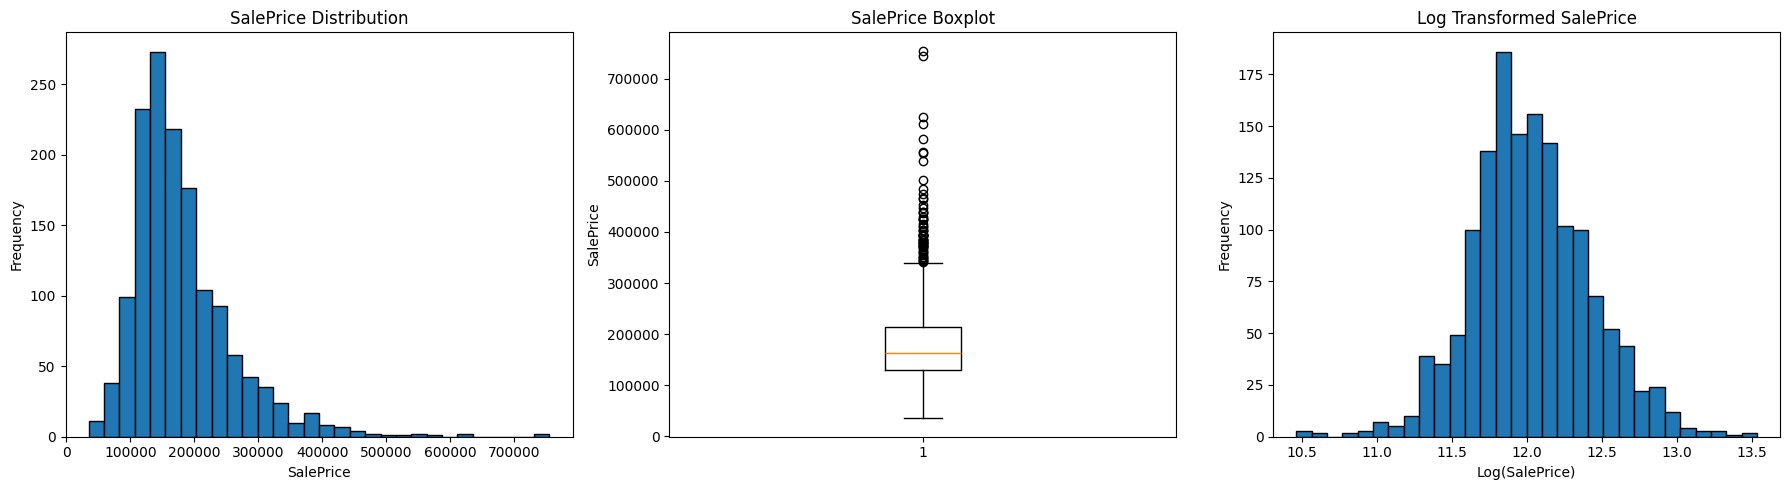

In [243]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))


axes[0].hist(df["SalePrice"], bins=30, edgecolor="black")
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("SalePrice")
axes[0].set_ylabel("Frequency")

axes[1].boxplot(df["SalePrice"])
axes[1].set_title("SalePrice Boxplot")
axes[1].set_ylabel("SalePrice")


log_price = np.log1p(df["SalePrice"])

axes[2].hist(log_price, bins=30, edgecolor="black")
axes[2].set_title("Log Transformed SalePrice")
axes[2].set_xlabel("Log(SalePrice)")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [244]:
print("Original SalePrice Skewness:", df["SalePrice"].skew())
print("Log SalePrice Skewness:", log_price.skew())

Original SalePrice Skewness: 1.8828757597682129
Log SalePrice Skewness: 0.12134661989685333


<Figure size 1200x600 with 0 Axes>

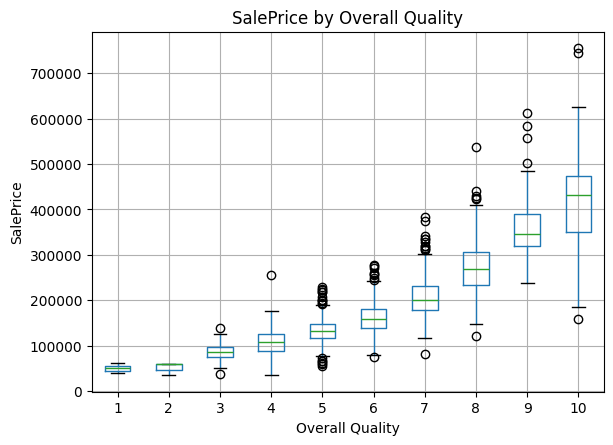

In [245]:
plt.figure(figsize=(12, 6))

df.boxplot(column="SalePrice", by="OverallQual")

plt.title("SalePrice by Overall Quality")
plt.suptitle("")
plt.xlabel("Overall Quality")
plt.ylabel("SalePrice")
plt.show()

<Figure size 1600x700 with 0 Axes>

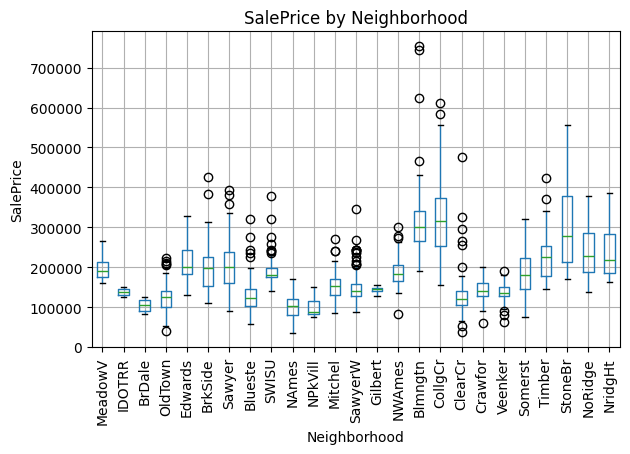

In [246]:
neighborhood_order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(16, 7))

df.boxplot(
    column="SalePrice",
    by="Neighborhood",
    positions=range(1, len(neighborhood_order) + 1)
)

plt.title("SalePrice by Neighborhood")
plt.suptitle("")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice")
plt.xticks(
    ticks=range(1, len(neighborhood_order) + 1),
    labels=neighborhood_order,
    rotation=90
)

plt.tight_layout()
plt.show()

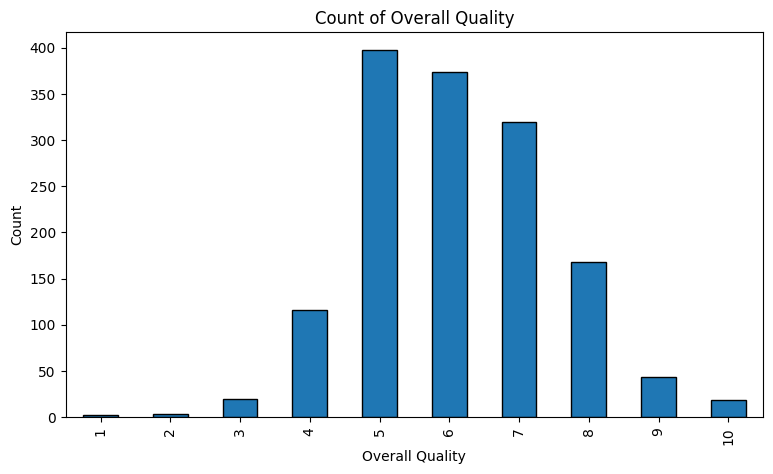

In [247]:

plt.figure(figsize=(9, 5))

df["OverallQual"].value_counts().sort_index().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Count of Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Count")
plt.show()

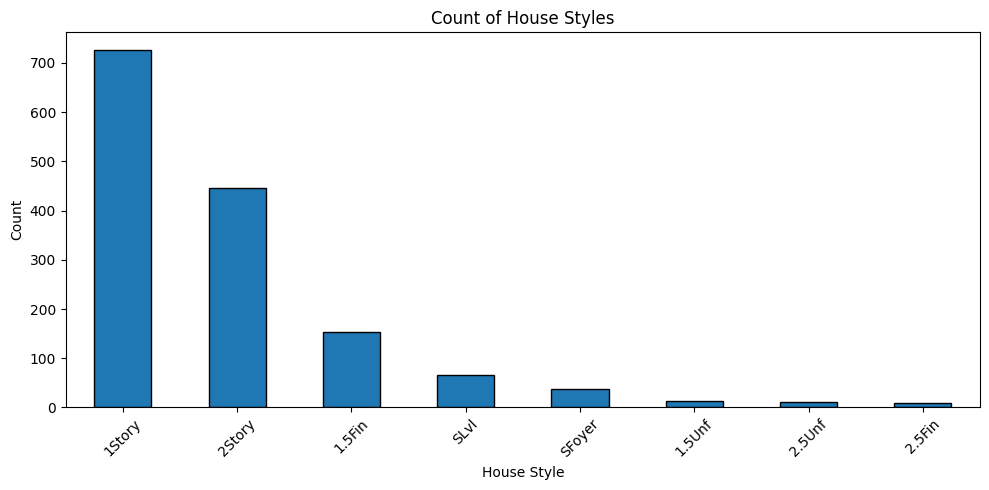

In [248]:
plt.figure(figsize=(10, 5))

df["HouseStyle"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Count of House Styles")
plt.xlabel("House Style")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Distribution Analysis – Observations
- SalePrice shows a positively (right) skewed distribution.
- The boxplot helps identify potential outliers in house prices.
- Log transformation reduces the skewness of SalePrice and makes its distribution more symmetrical.
- Houses with higher OverallQual generally have higher SalePrice.
- SalePrice varies across different Neighborhoods.
- OverallQual shows the frequency distribution of different house quality ratings.
- HouseStyle shows the frequency of different house designs.

# BIVARIATE AND MULTIVARIATE ANALYSIS

In [249]:
cov_matrix = df.select_dtypes(include=np.number).cov()
corr_matrix = df.select_dtypes(include=np.number).corr(method="pearson")

In [250]:
top_corr = corr_matrix["SalePrice"].abs().sort_values(ascending=False)
print("Top 10 Features Correlated with SalePrice:")
display(top_corr.head(11))

Top 10 Features Correlated with SalePrice:


,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


In [251]:
top_3 = top_corr.drop("SalePrice").head(3).index
print("\nTop 3 Features:")

for column in top_3:
    print("\nFeature:", column)
    print("Covariance with SalePrice:", cov_matrix.loc[column, "SalePrice"])
    print("Correlation with SalePrice:", corr_matrix.loc[column, "SalePrice"])


Top 3 Features:

Feature: OverallQual
Covariance with SalePrice: 86904.12583679946
Correlation with SalePrice: 0.7909816005838053

Feature: GrLivArea
Covariance with SalePrice: 29581866.743236575
Correlation with SalePrice: 0.7086244776126515

Feature: GarageCars
Covariance with SalePrice: 38020.18135897172
Correlation with SalePrice: 0.6404091972583519


In [252]:
ordinal_cols = ["OverallQual", "ExterQual", "KitchenQual"]
ordinal_data = df[ordinal_cols].copy()

for column in ["ExterQual", "KitchenQual"]:
    ordinal_data[column] = ordinal_data[column].cat.codes

spearman_corr = ordinal_data.corr(method="spearman")

print("Spearman Correlation:")
display(spearman_corr)

Spearman Correlation:


,OverallQual,ExterQual,KitchenQual
OverallQual,1.000000,0.715988,0.660498
ExterQual,0.715988,1.000000,0.725266
KitchenQual,0.660498,0.725266,1.000000


Correlation and Covariance – Observations
- Correlation measures the strength and direction of the relationship between two variables.
- Covariance indicates whether two variables move together or in opposite directions.
- Correlation is easier to interpret and compare because its values always lie between -1 and +1.
- Covariance depends on the measurement units and scales of the variables.
- SalePrice generally shows a positive relationship with important features such as OverallQual and GrLivArea.
- GarageArea and GarageCars also show a positive correlation because larger garages generally accommodate more cars.
- Highly correlated features may provide overlapping information, which is important when analysing relationships between variables.
Important Note: Correlation does not imply causation. A strong correlation between two variables does not necessarily mean that one variable causes a change in the other.

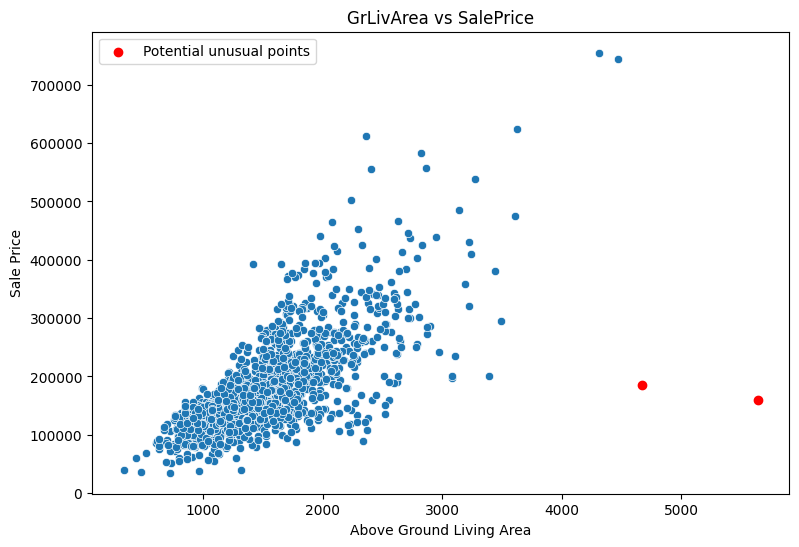

In [253]:
# Scatter plot
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice")
outliers = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]

plt.scatter(
    outliers["GrLivArea"],
    outliers["SalePrice"],
    color="red",
    label="Potential unusual points"
)

plt.title("GrLivArea vs SalePrice")
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")
plt.legend()
plt.show()

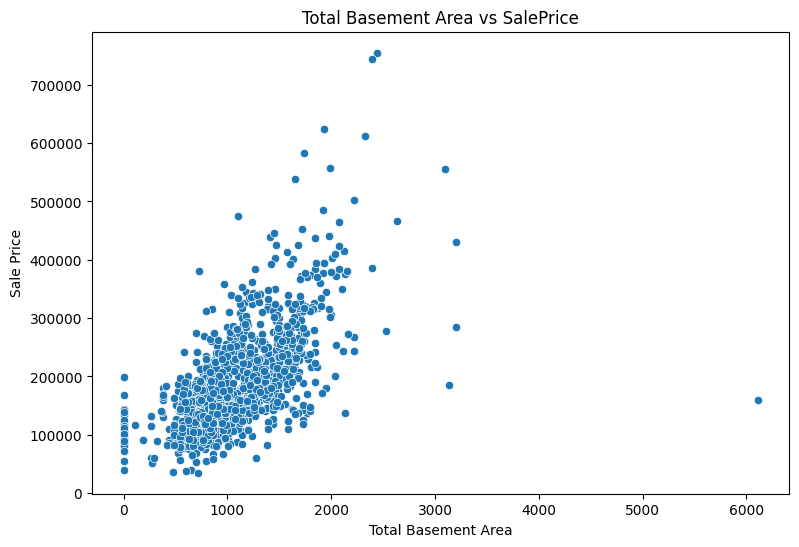

In [254]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice")

plt.title("Total Basement Area vs SalePrice")
plt.xlabel("Total Basement Area")
plt.ylabel("Sale Price")
plt.show()

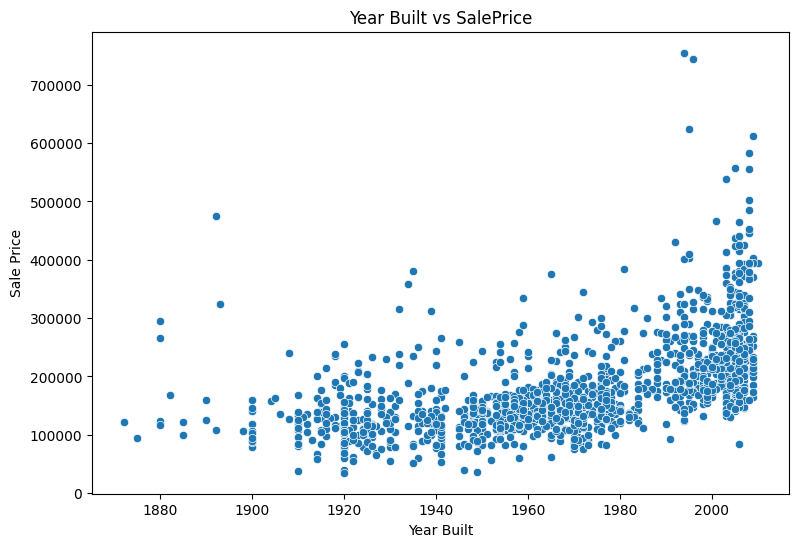

In [255]:
plt.figure(figsize=(9, 6))

sns.scatterplot(data=df, x="YearBuilt", y="SalePrice")

plt.title("Year Built vs SalePrice")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")
plt.show()

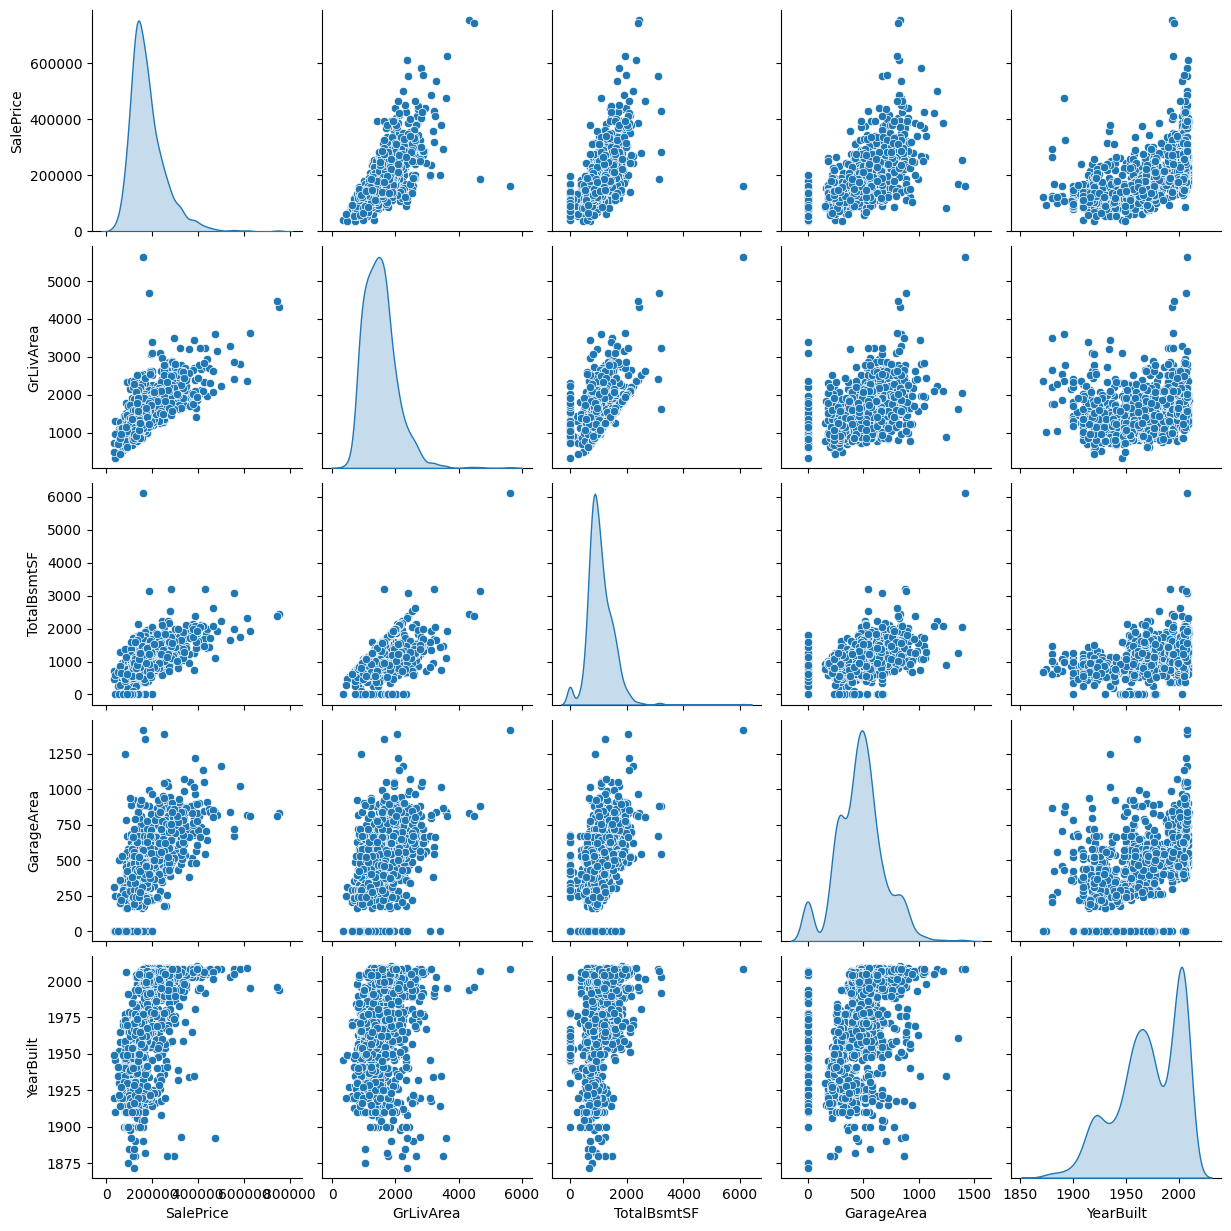

In [256]:
selected = [
    "SalePrice",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt"
]
sns.pairplot(
    df[selected],
    diag_kind="kde"
)

plt.show()

Scatter Plots and Pair Plot – Observations
- GrLivArea generally shows a positive relationship with SalePrice, meaning houses with larger living areas tend to have higher selling prices.
- A few houses have unusually large living areas but comparatively low selling prices.
- TotalBsmtSF generally shows a positive relationship with SalePrice, indicating that houses with larger basement areas tend to be more expensive.
- Newer houses tend to have higher selling prices, although some exceptions exist.
- Pair plots help visualise relationships and patterns between multiple numerical features simultaneously.

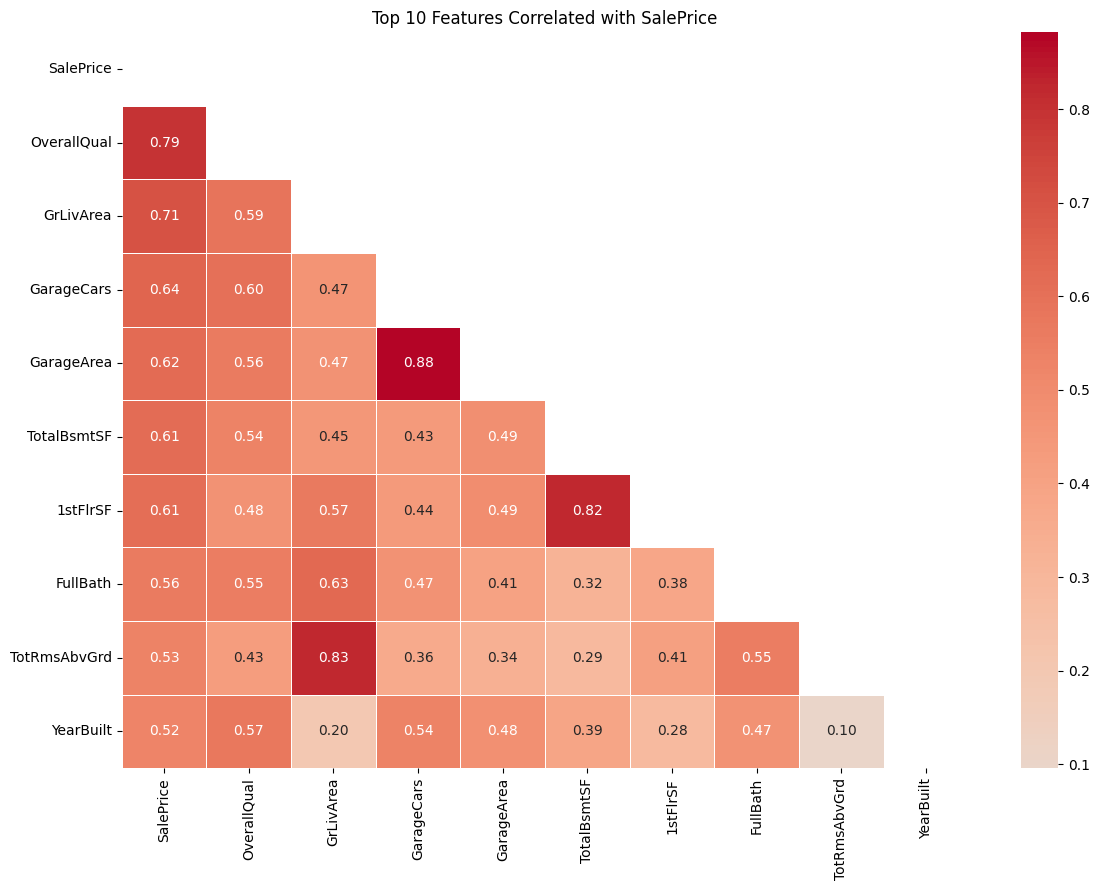

In [257]:
top10 = corr_matrix["SalePrice"].abs().sort_values(
    ascending=False
).head(10).index
corr_top = df[top10].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))


plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_top,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    mask=mask,
    linewidths=0.5
)

plt.title("Top 10 Features Correlated with SalePrice")
plt.tight_layout()
plt.show()

Correlation Heatmap – Observations
- The heatmap shows the correlation between the top 10 numerical features.
- Darker shades indicate stronger relationships between variables.
- Positive correlation means two features tend to increase together.
- Negative correlation means one feature tends to decrease as the other increases.
- OverallQual and GrLivArea generally show strong positive correlations with SalePrice.
- GarageCars and GarageArea also show a strong positive relationship with each other.

# OUTLIER ANALYSIS

In [258]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return series[(series < lower) | (series > upper)]

In [259]:
def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()

    return series[abs(z) > threshold]

In [260]:
for column in ["GrLivArea", "SalePrice"]:

    a = iqr_outliers(df[column])
    b = zscore_outliers(df[column])

    print("\nColumn:", column)
    print("IQR Outliers:", len(a))
    print("Z-score Outliers:", len(b))
    overlap = set(a.index).intersection(set(b.index))

    print("Common Outliers:", len(overlap))


Column: GrLivArea
IQR Outliers: 31
Z-score Outliers: 16
Common Outliers: 16

Column: SalePrice
IQR Outliers: 61
Z-score Outliers: 22
Common Outliers: 22


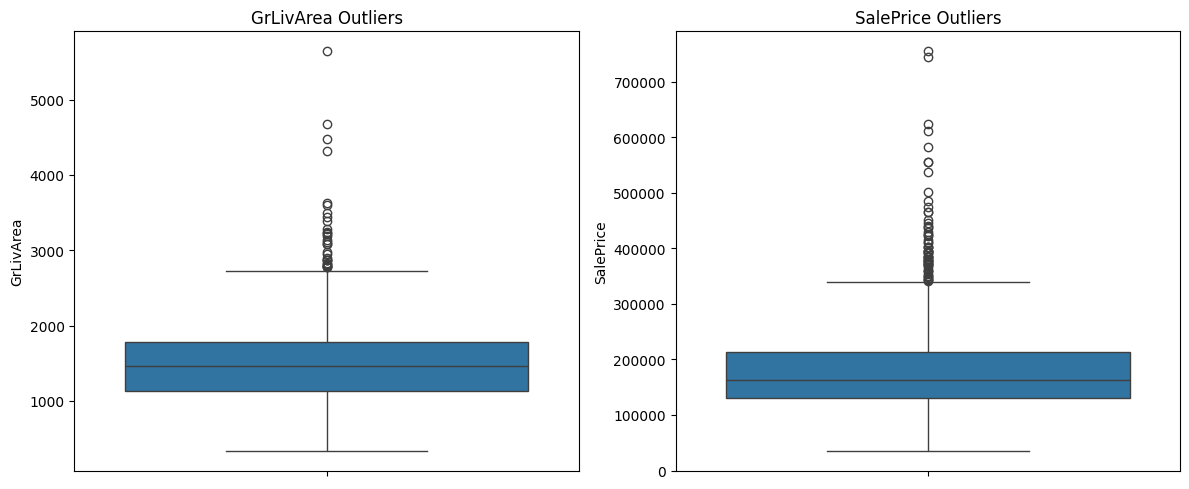

In [261]:
# boxplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=df["GrLivArea"], ax=axes[0])
axes[0].set_title("GrLivArea Outliers")

sns.boxplot(y=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Outliers")
plt.tight_layout()
plt.show()

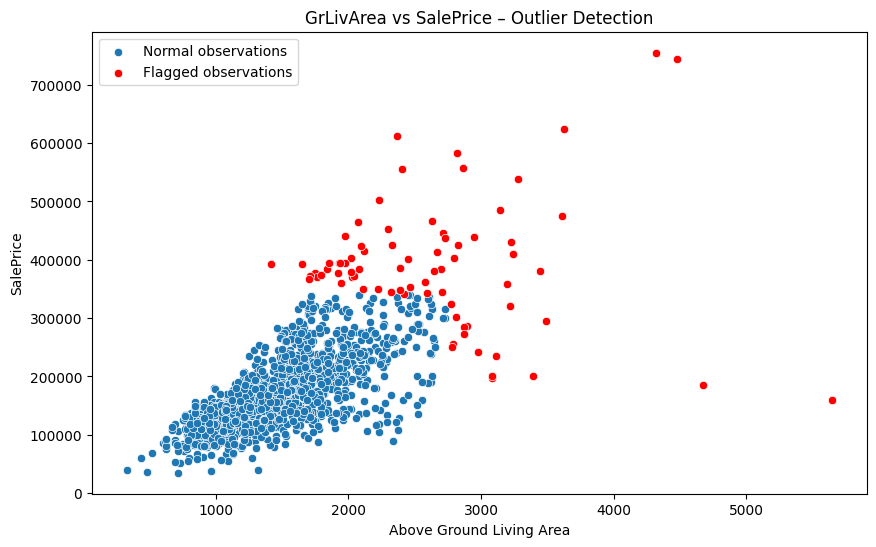

In [262]:
grliv_outliers = iqr_outliers(df["GrLivArea"])
saleprice_outliers = iqr_outliers(df["SalePrice"])

flagged_indices = set(grliv_outliers.index).union(
    set(saleprice_outliers.index)
)

normal = df.loc[~df.index.isin(flagged_indices)]
flagged = df.loc[list(flagged_indices)]

# scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=normal,
    x="GrLivArea",
    y="SalePrice",
    label="Normal observations"
)

sns.scatterplot(
    data=flagged,
    x="GrLivArea",
    y="SalePrice",
    color="red",
    label="Flagged observations"
)

plt.title("GrLivArea vs SalePrice – Outlier Detection")
plt.xlabel("Above Ground Living Area")
plt.ylabel("SalePrice")
plt.legend()
plt.show()

In [263]:
df_clean = df.copy()
display(
    df_clean.loc[list(flagged_indices),
                 ["GrLivArea", "SalePrice", "OverallQual", "YearBuilt"]]
)

,GrLivArea,SalePrice,OverallQual,YearBuilt
1024,2898,287000,8,1976
769,3279,538000,8,2003
515,2020,402861,10,2009
774,1973,395000,8,2006
1031,3082,197000,7,1920
...,...,...,...,...
481,1792,374000,9,2003
231,2794,403000,8,1995
496,3228,430000,8,1992
1267,2018,378500,9,2008


Outlier Detection – Observations
- Outliers were identified using IQR and Z-score methods.
- The IQR method identifies observations outside the interquartile range limits.
- The Z-score method identifies observations that are far from the mean in terms of standard deviations.
- Both methods may identify different numbers of outliers.
- Some houses have unusually large living areas or unusually high sale prices.
- Outliers are not necessarily incorrect data, as they may represent genuine properties with unusual characteristics.
Interpretation
- The Z-score method may identify fewer outliers than the IQR method for skewed variables because it uses the mean and standard deviation, which can be influenced by extreme values.
- The IQR method uses quartiles and is more resistant to extreme observations.
- Therefore, the IQR method is generally more suitable for detecting outliers in skewed distributions.
- Outliers should be investigated before removing them because they may represent genuine house sales rather than data-entry errors.

# DASHBOARD

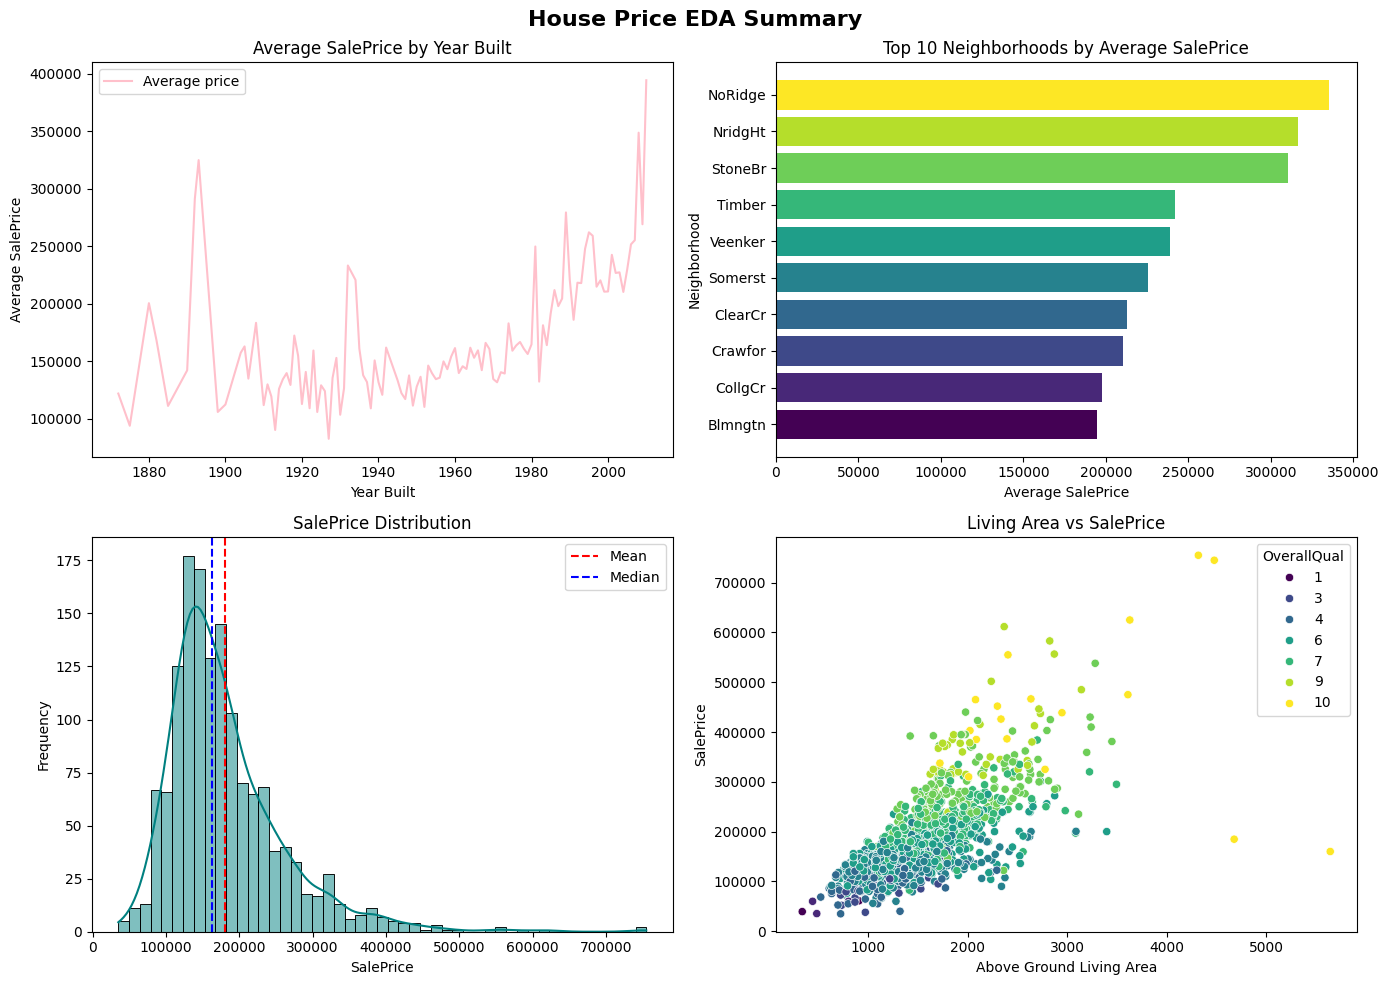

In [264]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
palette = "viridis"


yearly_price = df.groupby("YearBuilt")["SalePrice"].mean()

axes[0, 0].plot(
    yearly_price.index,
    yearly_price.values,
    color="pink",
    label="Average price"
)

axes[0, 0].set_title("Average SalePrice by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average SalePrice")
axes[0, 0].legend()


neighborhood_price = (
    df.groupby("Neighborhood")["SalePrice"]
    .mean()
    .nlargest(10)
    .sort_values()
)

axes[0, 1].barh(
    neighborhood_price.index,
    neighborhood_price.values,
    color=plt.cm.viridis(np.linspace(0, 1, 10))
)

axes[0, 1].set_title("Top 10 Neighborhoods by Average SalePrice")
axes[0, 1].set_xlabel("Average SalePrice")
axes[0, 1].set_ylabel("Neighborhood")



sns.histplot(
    data=df,
    x="SalePrice",
    kde=True,
    color="teal",
    ax=axes[1, 0]
)

mean_price = df["SalePrice"].mean()
median_price = df["SalePrice"].median()

axes[1, 0].axvline(
    mean_price,
    color="red",
    linestyle="--",
    label="Mean"
)

axes[1, 0].axvline(
    median_price,
    color="blue",
    linestyle="--",
    label="Median"
)

axes[1, 0].set_title("SalePrice Distribution")
axes[1, 0].set_xlabel("SalePrice")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].legend()



sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    palette=palette,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Living Area vs SalePrice")
axes[1, 1].set_xlabel("Above Ground Living Area")
axes[1, 1].set_ylabel("SalePrice")



fig.suptitle(
    "House Price EDA Summary",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

Final EDA Dashboard – Key Findings
1. Year Built:
- Average house prices show variations across construction years.
- Newer houses generally tend to have higher selling prices.
2. Neighborhood:
- Average house prices vary significantly across different neighborhoods.
- Some neighborhoods have considerably higher average selling prices than others.
3. SalePrice Distribution:
- SalePrice has a positively (right) skewed distribution.
- The mean is greater than the median because a few expensive properties increase the average price.
4. Living Area and Quality:
- GrLivArea generally shows a positive relationship with SalePrice.
- Houses with higher OverallQual ratings tend to have higher selling prices.



# CONCLUSIONS


The Exploratory Data Analysis of the Ames Housing dataset reveals that house prices are associated with several property characteristics, including living area, overall quality, construction year, and neighborhood.

Correlation and visualisation techniques helped identify important relationships, patterns, distributions, and unusual observations in the dataset.

The analysis provides a better understanding of the factors associated with house prices without applying machine learning techniques.

**Insights**

Q1. Is SalePrice right-skewed, and does a log transformation make it close to normal?

Answer: SalePrice shows a positively (right) skewed distribution. Applying a log transformation reduces the skewness and makes the distribution closer to a normal distribution.

Q2. Which numerical features correlate most strongly with SalePrice?

Answer: OverallQual and GrLivArea are among the strongest positively correlated features with SalePrice. This indicates that houses with better overall quality and larger living areas generally have higher selling prices.

Q3. Does price rise steadily with quality, and is there a larger spread at the top?

Answer: Yes. House prices generally increase as OverallQual increases. Higher-quality houses also show a wider variation in selling prices.

Q4. Do a few neighborhoods have clearly higher median prices than the rest?

Answer: Yes. Some neighborhoods have considerably higher median house prices than others, showing that location plays an important role in house prices.

Q5. Are a few very large houses with low prices likely unusual sales that distort trend lines?

Answer: Yes. A few houses have unusually large living areas but comparatively low selling prices. These may represent unusual sales and can affect the overall trend lines. They should be investigated before being removed.

Q6. Are many apparent missing values actually indications that a feature is absent?

Answer: Yes. Many missing values in the Ames Housing dataset represent the absence of a feature rather than unknown information. For example, missing values in PoolQC, Fence and FireplaceQu may indicate that the house does not have a pool, fence or fireplace. These values should be handled appropriately rather than automatically dropped.